# Assignment 5
Due Oct. 15

Yazdan Zinati 
260928077   

Dataset with brain atlas A for classification tasks: for the first set of 5 small programming
tasks use the Oasis dataset provided by the nilearn package, which can be downloaded
using the code below. This is a dataset of structural brain scans (aka voxel-based
morphometry) for male and female individuals.

In [2]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib

def fetch_oasis_dataset(n_rois, debug=False):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018( n_rois=n_rois)
    # this needs to be modified for some tasks
    masker = NiftiLabelsMasker(labels_img=yeo.maps, standardize=True,
    memory='nilearn_cache')
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(brain_data.ext_vars.mf == 'F',
    dtype=int) # gives 1 for females and 0 for males

    if debug:
        print(
            "Fetched dataset.\n" "input variables shape:",
            input_variables.shape,
            "\n",
            "output variable shape",
            output_variable.shape,
            )
    return input_variables, output_variable

1. Use sklearn.neighbors.KNeighborsClassifier(n_neighbors=5) and
sklearn.linear_model.LogisticRegression(penalty=’l2’, hyperparameter C set to 1.0)
to fit separate predictive models based on 100, 200, 300, …, 900, 1000 brain regions
of interest (see ‘n_rois’ argument for datasets.fetch_atlas_schaefer_2018) based on
the first 80% of the 100 structural brain scans to predict sex. Next, evaluate each
fitted LogReg / kNN model on the unseen final 20% of the 100 structural brain scans
and retrieve classification accuracy in XX.YY%. Please plot the classification
accuracy on the test set (x axis=the different atlas resolutions, y axis=prediction
accuracy on test set, 2 lines with 2 colors for the 2 different prediction model
classes).

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

num_regions = range(100, 1100, 100)
knn_scores, lr_scores = [], []

for n_rois in num_regions:
    input_variables, output_variable = fetch_oasis_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    knn = KNeighborsClassifier(n_neighbors=5)
    lr = LogisticRegression(penalty="l2", C=1.0)
    knn.fit(train_x, train_y)
    lr.fit(train_x, train_y)

    knn_scores.append(knn.score(test_x, test_y))
    lr_scores.append(lr.score(test_x, test_y))

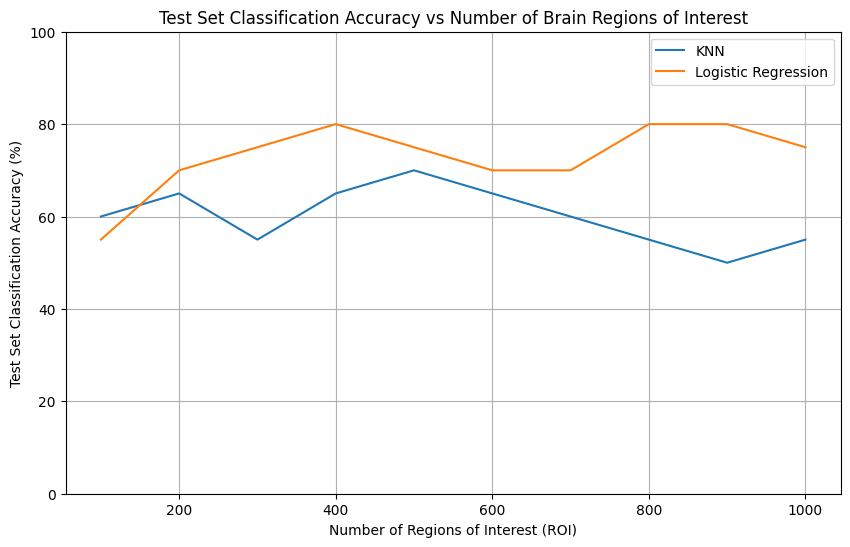

In [4]:
import matplotlib.pyplot as plt

knn_scores = np.array(knn_scores) * 100
lr_scores = np.array(lr_scores) * 100
plt.figure(figsize=(10, 6))
plt.plot(list(num_regions), knn_scores, label="KNN")
plt.plot(list(num_regions), lr_scores, label="Logistic Regression")
plt.title('Test Set Classification Accuracy vs Number of Brain Regions of Interest')
plt.xlabel("Number of Regions of Interest (ROI)")
plt.ylabel("Test Set Classification Accuracy (%)")
plt.ylim([0, 100])
plt.grid(True)
plt.legend()
plt.show()

2. Use sklearn.neighbors.KNeighborsClassifier() to fit separate predictive kNN models
based on 100 brain regions of interest (see ‘n_rois’ argument for
datasets.fetch_atlas_schaefer_2018) using n_neighbors=1,2,3,4,…10 and based on
the first 80% of the 100 structural brain scans to predict sex. Next, evaluate each
fitted kNN model on the unseen final 20% of the 100 structural brain scans andretrieve classification accuracy in XX.YY%. Please plot the classification accuracy on
the test set (x axis=number of neighbors, y axis=prediction accuracy on test set).

In [5]:
n_neighbors = range(1, 11)
knn_scores = []
n_rois = 100

input_variables, output_variable = fetch_oasis_dataset(n_rois)
for n in n_neighbors:
    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    knn = KNeighborsClassifier(n_neighbors=n)
    knn.fit(train_x, train_y)
    knn_scores.append(knn.score(test_x, test_y))

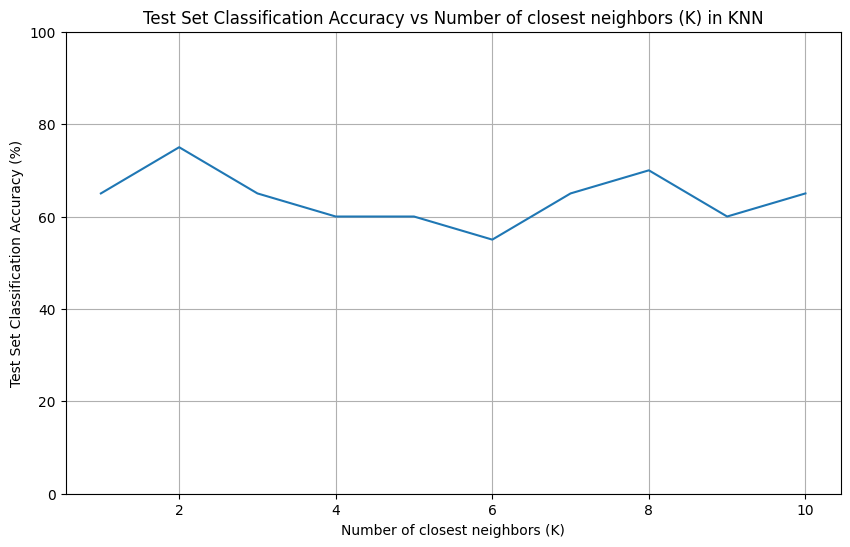

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(list(n_neighbors), np.array(knn_scores) * 100)
plt.title('Test Set Classification Accuracy vs Number of closest neighbors (K) in KNN')
plt.xlabel("Number of closest neighbors (K)")
plt.ylabel("Test Set Classification Accuracy (%)")
plt.ylim([0, 100])
plt.grid(True)
plt.show()

3. Use sklearn.neighbors.KNeighborsClassifier() to fit separate predictive kNN models
based on 100 brain regions of interest (see ‘n_rois’ argument for
datasets.fetch_atlas_schaefer_2018) using n_neighbors=1,2,3,4,…10 and based on
the full 100% of the 100 structural brain scans to predict sex. Next, evaluate each
fitted kNN model on same the 100 structural brain scans and retrieve classification
accuracy in XX.YY%. Please plot the classification accuracy on these 100 scans (x
axis=the different atlas resolutions, y axis=prediction accuracy). [Think about why
kNN shows this performance behavior as a function of its hyperparameter k!]

In [8]:
n_neighbors = range(1, 11)
knn_scores = []
n_rois = 100

input_variables, output_variable = fetch_oasis_dataset(n_rois)
for n in n_neighbors:
    train_x, test_x, train_y, test_y = (
        input_variables,
        input_variables,
        output_variable,
        output_variable,
    )

    knn = KNeighborsClassifier(n_neighbors=n)
    knn.fit(train_x, train_y)
    knn_scores.append(knn.score(test_x, test_y))

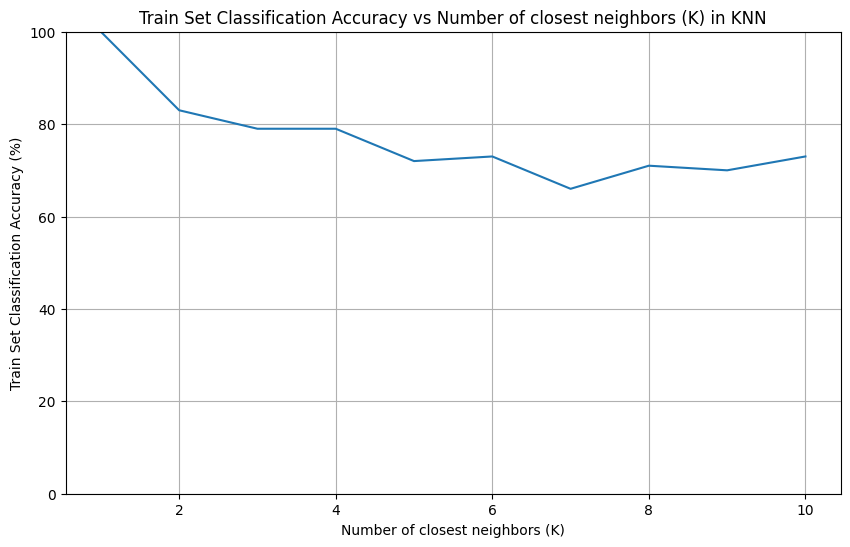

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(list(n_neighbors), np.array(knn_scores) * 100)
plt.title('Train Set Classification Accuracy vs Number of closest neighbors (K) in KNN')
plt.xlabel("Number of closest neighbors (K)")
plt.ylabel("Train Set Classification Accuracy (%)")
plt.ylim([0, 100])
plt.grid(True)
plt.show()  

We see that the model overfits with a small k obviously as we are also using not test set for evaluation.

4. Use KNeighborsClassifier(n_neighbors=3) and LogisticRegression(penalty=’l2’,
C=1.0) to fit separate predictive models using the lowest resolution brain scan data
(100 ROIs). Train each model to predict sex based on the first 10, 20, 30, …, 80 of
the 100 subjects (you will fit 8 models of each type). Next, evaluate each fitted
LogReg / kNN model on the unseen final 20 subjects and calculate classification
accuracy. Report these test accuracies in a table to two significant figures (eg.
89.05%). Plot the classification accuracy on the test set (number of training subjects
on x-axis (10-80), prediction accuracy on test set on the y-axis; there should be one
line for each model and a legend).

In [23]:
lr_scores, knn_scores = [], []
n_rois = 100
input_variables, output_variable = fetch_oasis_dataset(n_rois)

n_samples = range(10, 90, 10)
for s in n_samples:
    train_x, test_x, train_y, test_y = (
        input_variables[:s],
        input_variables[80:],
        output_variable[:s],
        output_variable[80:],
    )

    knn = KNeighborsClassifier(n_neighbors=3)
    lr = LogisticRegression(penalty="l2", C=1.0)
    knn.fit(train_x, train_y)
    knn_scores.append(knn.score(test_x, test_y))
    lr.fit(train_x, train_y)
    lr_scores.append(lr.score(test_x, test_y))

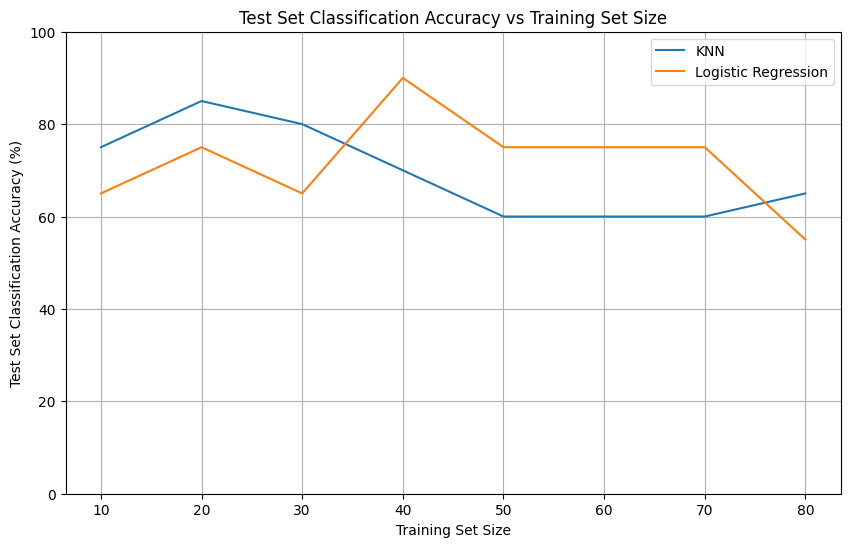

In [24]:
knn_scores = np.array(knn_scores) * 100
lr_scores = np.array(lr_scores) * 100
plt.figure(figsize=(10, 6))
plt.plot(list(n_samples), knn_scores, label="KNN")
plt.plot(list(n_samples), lr_scores, label="Logistic Regression")
plt.title('Test Set Classification Accuracy vs Training Set Size')
plt.xlabel("Training Set Size")
plt.ylabel("Test Set Classification Accuracy (%)")
plt.ylim([0, 100])
plt.grid(True)
plt.legend()
plt.show()

In [25]:
import pandas as pd 

# knn_scores = np.round(knn_scores, 2)
# lr_scores = np.round(lr_scores, 2)

data = {
    "Train Set size": list(n_samples),
    "KNN Accuracy (%)": knn_scores,
    "Logistic Regression Accuracy (%)": lr_scores
}

df = pd.DataFrame(data)
df

,Train Set size,KNN Accuracy (%),Logistic Regression Accuracy (%)
0,10,75.0,65.0
1,20,85.0,75.0
2,30,80.0,65.0
3,40,70.0,90.0
4,50,60.0,75.0
5,60,60.0,75.0
6,70,60.0,75.0
7,80,65.0,55.0


5. Use KNeighborsClassifier(n_neighbors=3) and LogisticRegression(penalty=’l2’,
C=1.0) to fit separate predictive models using the lowest resolution brain scan data
(100 ROIs). Using the first 80 subjects as the training set, train each model to predict
sex based on the first 10, 20, 30,…,100 ROIs (you will fit 10 models of each type).
Next, evaluate each fitted LogReg / kNN model on the unseen final 20 subjects and
calculate classification accuracy. Report these test accuracies in a table to two
significant figures (eg. 89.05%). Plot the classification accuracy on the test set
(number of ROIs on x-axis (10-100), prediction accuracy on test set on the y-axis;
there should be one line for each model and a legend).

In [26]:
lr_scores, knn_scores = [], []
n_rois = 100
input_variables, output_variable = fetch_oasis_dataset(n_rois)

n_rois = range(10, 110, 10)
for n_roi in n_rois:
    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    knn = KNeighborsClassifier(n_neighbors=3)
    lr = LogisticRegression(penalty="l2", C=1.0)
    knn.fit(train_x[:, :n_roi], train_y)
    knn_scores.append(knn.score(test_x[:, :n_roi], test_y))
    lr.fit(train_x[:, :n_roi], train_y)
    lr_scores.append(lr.score(test_x[:, :n_roi], test_y))

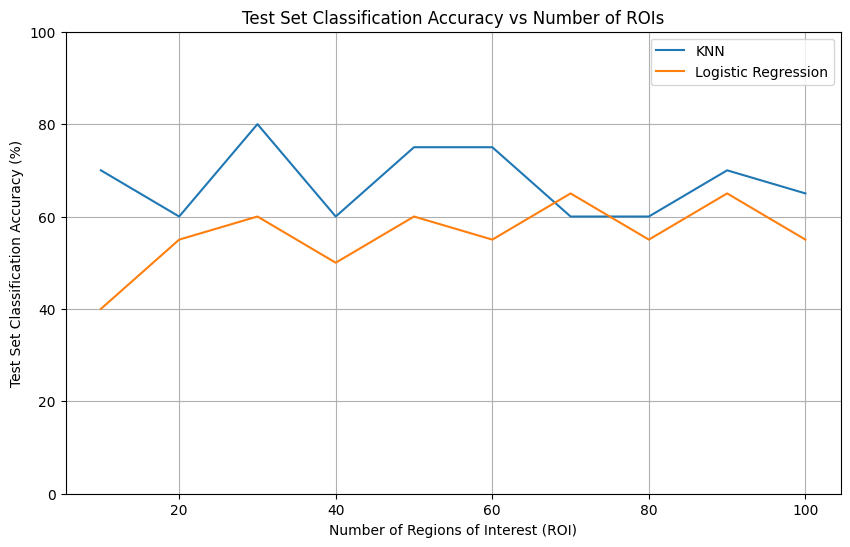

In [27]:
knn_scores = np.array(knn_scores) * 100
lr_scores = np.array(lr_scores) * 100
plt.figure(figsize=(10, 6))
plt.plot(list(n_rois), knn_scores, label="KNN")
plt.plot(list(n_rois), lr_scores, label="Logistic Regression")
plt.title('Test Set Classification Accuracy vs Number of ROIs')
plt.xlabel("Number of Regions of Interest (ROI)")
plt.ylabel("Test Set Classification Accuracy (%)")
plt.ylim([0, 100])
plt.grid(True)
plt.legend()
plt.show()

In [29]:
knn_scores = np.round(knn_scores, 2)
lr_scores = np.round(lr_scores, 2)

data = {
    "Number of ROIs": n_rois,
    "KNN Accuracy (%)": knn_scores,
    "Logistic Regression Accuracy (%)": lr_scores
}

df = pd.DataFrame(data)
df

,Number of ROIs,KNN Accuracy (%),Logistic Regression Accuracy (%)
0,10,70.0,40.0
1,20,60.0,55.0
2,30,80.0,60.0
3,40,60.0,50.0
4,50,75.0,60.0
5,60,75.0,55.0
6,70,60.0,65.0
7,80,60.0,55.0
8,90,70.0,65.0
9,100,65.0,55.0


Dataset with brain atlas B for continous prediction tasks: For the second set of 5 small
programming tasks use the Oasis dataset provided by the nilearn package, which can be
downloaded using the code below. This is a dataset of structural brain scans (aka voxel- based
morphometry) for male and female individuals.

In [30]:
import os 
def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        'scorr_mean': os.path.join(base_path, 'scorr05_mean_all.nii.gz'),
        'tcorr_mean': os.path.join(base_path, 'tcorr05_mean_all.nii.gz'),
        'scorr_2level': os.path.join(base_path, 'scorr05_2level_all.nii.gz'),
        'tcorr_2level': os.path.join(base_path, 'tcorr05_2level_all.nii.gz'),
        'random': os.path.join(base_path, 'random_all.nii.gz'),
        'description': 'Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.'
    }
    return craddock_data

In [31]:
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
from sklearn.preprocessing import StandardScaler
import nibabel as nib


def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    brain_data_dir = "/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/"
    crad = load_craddock_local(brain_data_dir)

    atlas_nii = index_img(crad["scorr_mean"], n_rois)
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age[:, None])[
        :, 0
    ]  # gives subject age on standard units after z-scoring
    return input_variables, output_variable

Note: use Ridge(default parameters) instead of LogisticRegression for the following
questions.

6. analogous to task 1, but predicting continuous subject age with
sklearn.neighbors.KNeighborsRegressor(n_neighbors=5) and using 43 different
versions of Craddock region atlas resolutions (.scorr_mean) instead of the 10 region
numbers from Dataset A. Use R2 coefficient of determination instead of classification
accuracy, which can be found at sklearn.metrics.r2_score.

In [33]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.neighbors import KNeighborsRegressor

num_regions = range(43)
knn_scores, lr_scores = [], []

for n_rois in num_regions:
    input_variables, output_variable = fetch_second_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    knn = KNeighborsRegressor(n_neighbors=5)
    lr = Ridge()
    knn.fit(train_x, train_y)
    lr.fit(train_x, train_y)

    knn_scores.append(knn.score(test_x, test_y))
    lr_scores.append(lr.score(test_x, test_y))

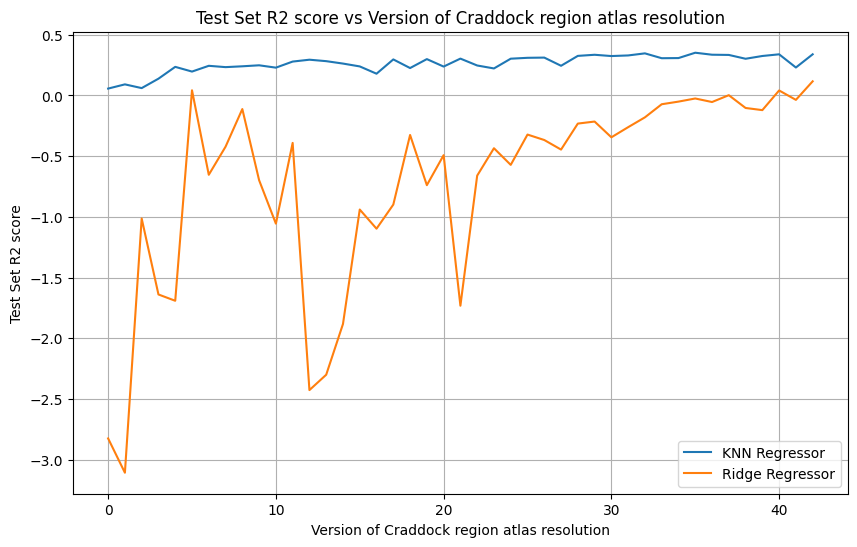

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(list(num_regions), knn_scores, label="KNN Regressor")
plt.plot(list(num_regions), lr_scores, label="Ridge Regressor")
plt.title('Test Set R2 score vs Version of Craddock region atlas resolution')
plt.xlabel("Version of Craddock region atlas resolution")
plt.ylabel("Test Set R2 score")
plt.grid(True)
plt.legend()
plt.show()

7. analogous to task 2, but predicting continuous subject age using
KNeighborsRegressor(n_neighbors=1…10) . Use crad[‘scorr_mean’] = 9.

In [35]:
n_neighbors = range(1, 11)
knn_scores = []

input_variables, output_variable = fetch_second_dataset(9)
for n in n_neighbors:
    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    knn = KNeighborsRegressor(n_neighbors=n)
    knn.fit(train_x, train_y)
    knn_scores.append(knn.score(test_x, test_y))

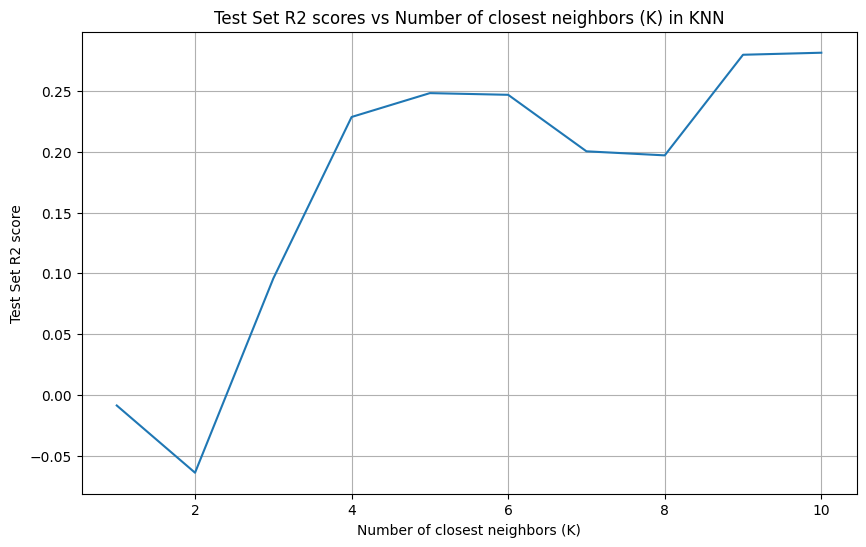

In [36]:
plt.figure(figsize=(10, 6))
plt.plot(list(n_neighbors), np.array(knn_scores))
plt.title('Test Set R2 scores vs Number of closest neighbors (K) in KNN')
plt.xlabel("Number of closest neighbors (K)")
plt.ylabel("Test Set R2 score")
plt.grid(True)
plt.show()

8. analogous to task 3, but predicting continuous subject age with
KNeighborsRegressor. Use crad[‘scorr_mean’] = 9.

In [37]:
n_neighbors = range(1, 11)
knn_scores = []

input_variables, output_variable = fetch_second_dataset(9)
for n in n_neighbors:
    train_x, test_x, train_y, test_y = (
        input_variables,
        input_variables,
        output_variable,
        output_variable,
    )

    knn = KNeighborsRegressor(n_neighbors=n)
    knn.fit(train_x, train_y)
    knn_scores.append(knn.score(test_x, test_y))

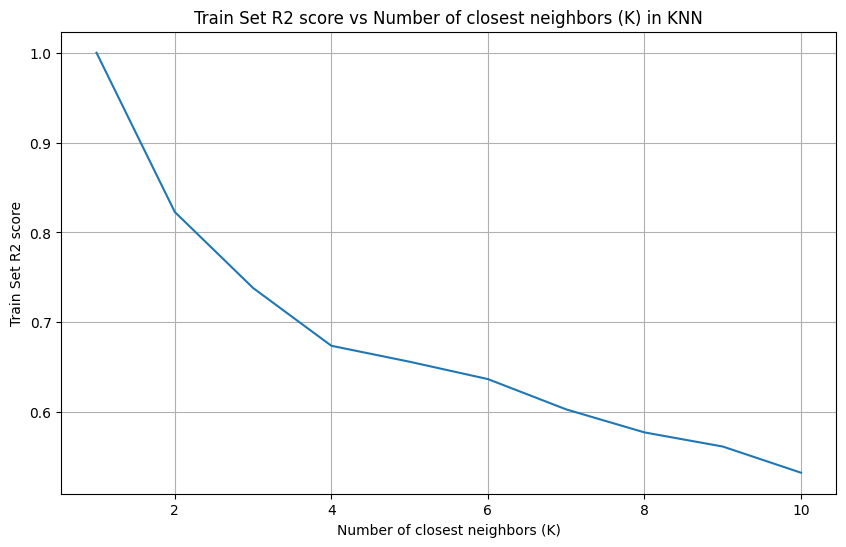

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(list(n_neighbors), np.array(knn_scores))
plt.title('Train Set R2 score vs Number of closest neighbors (K) in KNN')
plt.xlabel("Number of closest neighbors (K)")
plt.ylabel("Train Set R2 score")
plt.grid(True)
plt.show()

It's overfitting with small k. 

9. analogous to task 4, but predicting continuous subject age with
KNeighborsRegressor. Use crad[‘scorr_mean’] = 9.

In [40]:
lr_scores, knn_scores = [], []
input_variables, output_variable = fetch_second_dataset(9)

n_samples = range(10, 90, 10)
for s in n_samples:
    train_x, test_x, train_y, test_y = (
        input_variables[:s],
        input_variables[80:],
        output_variable[:s],
        output_variable[80:],
    )

    knn = KNeighborsRegressor(n_neighbors=3)
    lr = Ridge()
    knn.fit(train_x, train_y)
    knn_scores.append(knn.score(test_x, test_y))
    lr.fit(train_x, train_y)
    lr_scores.append(lr.score(test_x, test_y))

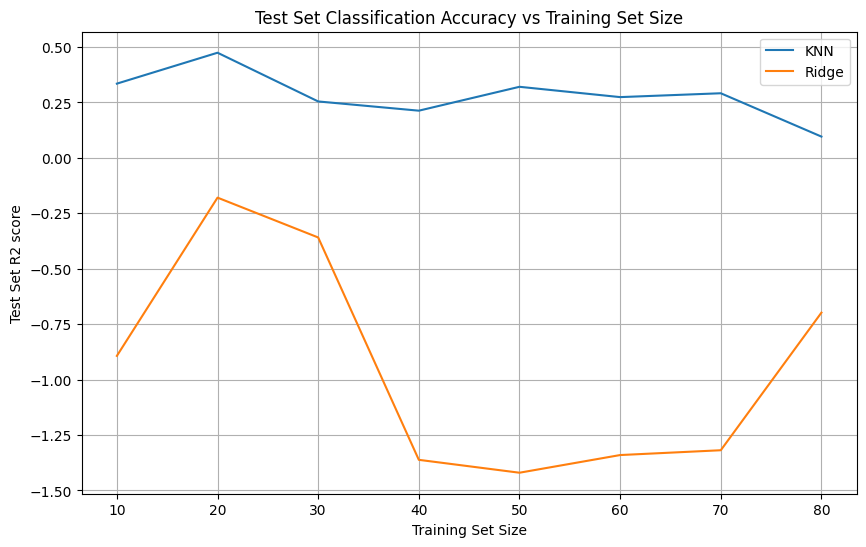

In [41]:
knn_scores = np.array(knn_scores)
lr_scores = np.array(lr_scores)
plt.figure(figsize=(10, 6))
plt.plot(list(n_samples), knn_scores, label="KNN")
plt.plot(list(n_samples), lr_scores, label="Ridge")
plt.title('Test Set Classification Accuracy vs Training Set Size')
plt.xlabel("Training Set Size")
plt.ylabel("Test Set R2 score")
plt.grid(True)
plt.legend()
plt.show()

In [42]:

knn_scores = np.round(knn_scores, 2)
lr_scores = np.round(lr_scores, 2)

data = {
    "Train Set size": list(n_samples),
    "KNN R2": knn_scores,
    "Ridge R2": lr_scores
}

df = pd.DataFrame(data)
df

,Train Set size,KNN R2,Ridge R2
0,10,0.33,-0.89
1,20,0.47,-0.18
2,30,0.25,-0.36
3,40,0.21,-1.36
4,50,0.32,-1.42
5,60,0.27,-1.34
6,70,0.29,-1.32
7,80,0.10,-0.70


10. analogous to task 5, but predicting continuous subject age with
KNeighborsRegressor. Use crad[‘scorr_mean’] = 9.

In [43]:
lr_scores, knn_scores = [], []
input_variables, output_variable = fetch_second_dataset(9)

n_rois = range(10, 110, 10)
for n_roi in n_rois:
    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    knn = KNeighborsRegressor(n_neighbors=3)
    lr = Ridge()
    knn.fit(train_x[:, :n_roi], train_y)
    knn_scores.append(knn.score(test_x[:, :n_roi], test_y))
    lr.fit(train_x[:, :n_roi], train_y)
    lr_scores.append(lr.score(test_x[:, :n_roi], test_y))

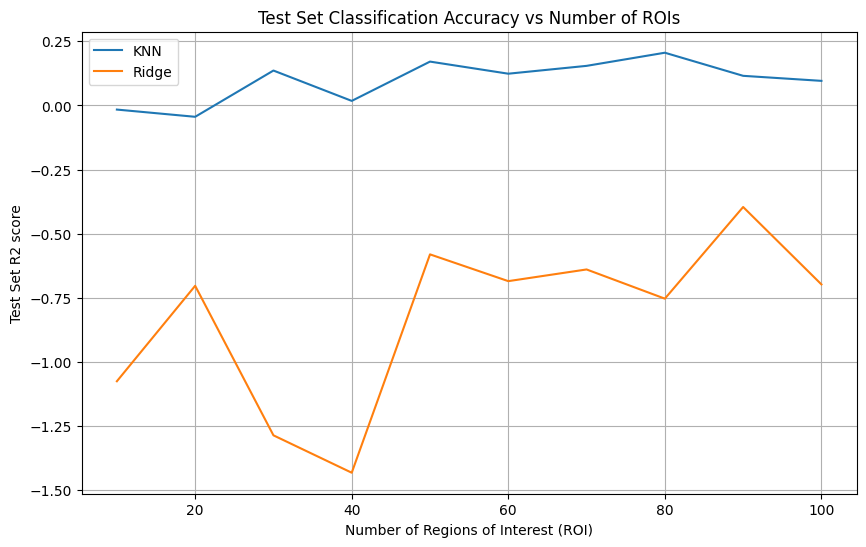

In [44]:
knn_scores = np.array(knn_scores)
lr_scores = np.array(lr_scores)
plt.figure(figsize=(10, 6))
plt.plot(list(n_rois), knn_scores, label="KNN")
plt.plot(list(n_rois), lr_scores, label="Ridge")
plt.title('Test Set Classification Accuracy vs Number of ROIs')
plt.xlabel("Number of Regions of Interest (ROI)")
plt.ylabel("Test Set R2 score")
plt.grid(True)
plt.legend()
plt.show()

In [46]:
knn_scores = np.round(knn_scores, 2)
lr_scores = np.round(lr_scores, 2)

data = {
    "Number of ROIs": n_rois,
    "KNN R2 score": knn_scores,
    "Logistic Regression R2 score": lr_scores
}

df = pd.DataFrame(data)
df

,Number of ROIs,KNN R2 score,Logistic Regression R2 score
0,10,-0.02,-1.08
1,20,-0.04,-0.70
2,30,0.14,-1.29
3,40,0.02,-1.43
4,50,0.17,-0.58
5,60,0.12,-0.69
6,70,0.15,-0.64
7,80,0.21,-0.75
8,90,0.12,-0.40
9,100,0.10,-0.70
